# Factor Risk Decomposition and Stress Testing

*How can the risk of a long/short book be translated into decisions a portfolio manager can act on, without cutting the positions that earn its return?*

**Short answer.** The toolkit works, and what it finds is not what a VaR ranking would say. The test book lost 2.5% a year from 2010 to 2026. Most of its risk came from an accidental bet (value and sector tilts, 29% of variance) rather than from the momentum and stock picks it was built on, and those intended bets earned close to nothing. Its worst days are driven by long bank positions, not by the volatile shorts that dominate everyday risk, and its most plausible 10% loss is a momentum reversal, which happens about once every 5 years under stress correlations. Re-allocating risk confirms it. Removing the accidental sector bet does the most good: a sector-neutral rebuild of the same signal lifts the Sharpe ratio from −0.16 to +0.10, cuts the worst drawdown from −46% to −19%, and cuts the November 2020 momentum-crash loss from −10.8% to −2.1%. Adding the factor hedge lifts it to +0.14. None of the gains clears a 90% bootstrap interval, and none turns this book into one worth running.

| Question | Finding | Section |
|---|---|---|
| Where does the book's risk come from? | Factors 70% of variance: value 29% (an accidental sector bet), momentum 26%; stock-specific 30%. All top-8 contributors are shorts. | 3 |
| Is each source of risk paid? | No. Momentum carried 39% of the variance and earned −0.2% a year; stock selection earned +0.9% (0.10 per unit of risk); the market exposure cost 1.9% a year. | 4 |
| What would past crises do to today's book? | −12.4% in 2008 (mostly stock-specific, from long banks), −14.0% in COVID, −8.1% in the 2023 bank failures; +34.6% in the 2022 rate shock. | 5 |
| What do hypothetical shocks do? | A momentum crash costs 5.4%, 6.2% with a 20% market fall. Market falls, rate rises and stagflation help the book. | 6 |
| How large is a bad month, and how wrong is the normal model? | One-month 99% ES: 12.4% under a normal model, 17.6% from stress days (1.43 times). Long banks drive the worst days. | 7 |
| What is the most plausible way to lose 10%? | A momentum reversal with a market rally: a 2.2-standard-deviation month under stress correlations, about once every 5 years. | 8 |
| Which re-allocation cuts stress losses without cutting return? | Sector-neutral rebuild: return −2.5% → +0.8%, volatility 15.8% → 8.4%, worst drawdown −46% → −19%, worst episode −10.8% → −3.5%. With the factor hedge, Sharpe ratio +0.14. Gains are likely but not statistically clear (90% interval −0.04 to +0.56). | 9 |

**Why it matters.** A risk report that only ranks positions by value at risk (VaR) pushes every book toward the same answer: cut the volatile names. In a long/short equity book those names are often where the return comes from. A good stress test separates two kinds of risk. Risk the book is paid for, such as its stock picks and its momentum tilt, should be sized and protected. Risk it is not paid for, such as an accidental bet on the market, oil or interest rates, should be hedged. The test also shows which events would hurt, by how much, and how plausible they are.

**Approach.**
1. Build a realistic long/short book: 90 US large caps, long the 20 best and short the 20 worst by momentum and stability, rebalanced monthly from 2010.
2. Break its risk into nine market factors and stock-specific risk.
3. Check which risks earned a return from 2010 to 2026 and which did not.
4. Replay past crises on today's book, including 2008, and apply hypothetical shocks that move all factors together in a realistic way.
5. Simulate a month of P&L with fat tails and stressed volatility, and search for the most plausible scenario that loses 10%.
6. Compare five ways to re-allocate against the original book: minimum volatility, hedging the unpaid factors, sizing by conviction, a sector-neutral rebuild, and a sector-neutral rebuild with the hedge.

**Use it when.** Writing the monthly risk review of a long/short book, deciding what to hedge before an event, or explaining to a PM why a risky position should stay.

**Data.** Daily adjusted closes from Yahoo Finance, Jan 2007 to Oct 2026: 90 US large-cap stocks in 10 sectors, 9 factor ETFs and 9 sector ETFs. Stocks that listed after 2007 enter when they have a year of history. The stock list holds today's large caps (survivorship bias), so backtest returns are flattering; the comparisons between risk methods are what matter.

**Contents.** 1 The data and the factors · 2 The book · 3 Where the risk comes from · 4 Paid and unpaid risk · 5 Historical replays · 6 Hypothetical scenarios · 7 Simulated bad months · 8 Reverse stress test · 9 Re-allocation · 10 The risk report · Conclusions

In [15]:
import sys, warnings
sys.path.insert(0, ".")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

import data_utils as du
import risk_tools as rt

du.set_style()
stock_px = du.load_prices("stocks", long_history=True)
etf_px = du.load_prices("etfs", long_history=True)
stock_r = du.load_returns("stocks", long_history=True)
etf_r = du.load_returns("etfs", long_history=True)
sector = pd.Series(du.sector_map())
print(f"stocks: {stock_px.shape[1]} tickers, {stock_px.index[0].date()} to {stock_px.index[-1].date()}")
print(f"ETFs:   {etf_px.shape[1]} tickers; latest first trade among stocks: {stock_px.apply(pd.Series.first_valid_index).max().date()}")

stocks: 91 tickers, 2007-01-03 to 2026-11-06
ETFs:   24 tickers; latest first trade among stocks: 2019-03-20


## 1 · The data and the factors

A long/short book is exposed to more than the stocks it holds. Nine **factors** describe the broad forces that move many stocks at once. Each is the daily return of a tradable portfolio, so any exposure to it can also be hedged with ETFs:

| Factor | Built as | What a positive exposure means |
|---|---|---|
| MKT | SPY | The book gains when the US market rises |
| SIZE | IWM minus SPY | Gains when small caps beat large caps |
| VALUE | VTV minus VUG | Gains when value stocks beat growth stocks |
| MOM | Top third minus bottom third of the 90 stocks by 12-1 month momentum | Gains when recent winners keep beating recent losers |
| RATES | IEF (7–10 year Treasuries) | Gains when bond yields fall |
| CREDIT | HYG minus IEF | Gains when high-yield credit spreads tighten |
| OIL | USO | Gains when crude oil rises |
| GOLD | GLD | Gains when gold rises |
| USD | UUP | Gains when the US dollar strengthens |

12-1 month momentum is the return from 12 months ago to 1 month ago; the latest month is skipped because very recent winners tend to give back part of their gain.

Before any model is built, the factors themselves show the first lesson of stress testing: in turbulent periods assets move together more than usual. The two heatmaps compare factor correlations on calm days and on stress days, defined as days when the market's trailing one-month volatility is in the top 10% of the sample.

factor history 2008-01-07 to 2026-11-06, 472 stress days of 4740
        annual return  annual vol  return / vol  vol on stress days / calm days
MKT             0.106       0.197         0.537                           3.092
SIZE           -0.021       0.114        -0.189                           1.822
VALUE          -0.029       0.117        -0.245                           1.453
MOM             0.014       0.162         0.085                           1.890
RATES           0.027       0.070         0.386                           1.663
CREDIT          0.021       0.134         0.160                           3.434
OIL            -0.076       0.385        -0.197                           2.144
GOLD            0.078       0.183         0.429                           1.693
USD             0.022       0.080         0.273                           1.861


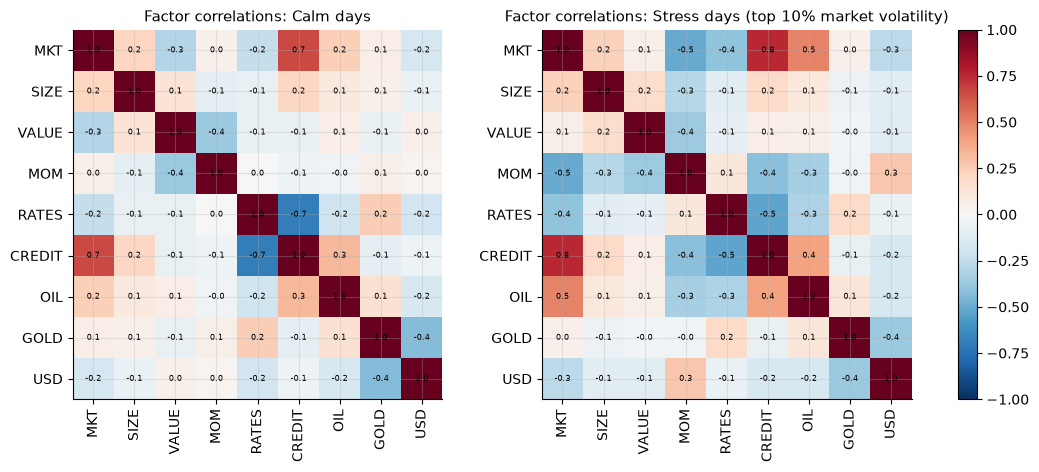

average absolute correlation between factors: calm 0.17, stress 0.22


In [16]:
F = rt.build_factor_returns(etf_r, stock_px, stock_r)
stress = rt.stress_days(etf_r["SPY"].loc[F.index])
calm = F.index.difference(stress)
ann = pd.DataFrame({"annual return": F.mean() * 252, "annual vol": F.std() * np.sqrt(252)})
ann["return / vol"] = ann["annual return"] / ann["annual vol"]
ann["vol on stress days / calm days"] = F.loc[stress].std() / F.loc[calm].std()
print(f"factor history {F.index[0].date()} to {F.index[-1].date()}, {len(stress)} stress days of {len(F)}")
print(ann.round(3).to_string())

c_calm, c_stress = F.loc[calm].corr(), F.loc[stress].corr()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, c, title in [(axes[0], c_calm, "Calm days"), (axes[1], c_stress, "Stress days (top 10% market volatility)")]:
    im = ax.imshow(c.values, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(c))); ax.set_xticklabels(c.columns, rotation=90); ax.set_yticks(range(len(c))); ax.set_yticklabels(c.index)
    for i in range(len(c)):
        for j in range(len(c)):
            ax.text(j, i, f"{c.values[i, j]:.1f}", ha="center", va="center", fontsize=6)
    ax.set_title(f"Factor correlations: {title}")
fig.colorbar(im, ax=axes, fraction=0.025)
plt.show()
off = ~np.eye(len(c_calm), dtype=bool)
print(f"average absolute correlation between factors: calm {np.abs(c_calm.values[off]).mean():.2f}, stress {np.abs(c_stress.values[off]).mean():.2f}")

- From 2008 to 2026 the market factor returned 10.6% a year at 19.7% volatility (0.54 per unit of volatility). Momentum among these 90 large caps returned only 1.4% a year at 16.2% (0.09): the book's main factor tilt has barely paid on its own.
- On stress days every factor is more volatile than on calm days: about 3 times for the market (3.1) and credit (3.4), 1.5 to 2.1 times for the rest.
- Correlations rise too. The average absolute correlation between factors is 0.17 on calm days and 0.22 on stress days, and in the stress heatmap the market, credit and oil move together more tightly.
- A risk model estimated on all days understates both the size of moves and how many factors move at once in a crisis. The scenarios below therefore use a covariance from stress days as well.

## 2 · The book

The book is built the way many systematic equity long/short books are: rank the stocks, buy the top, sell the bottom, and keep the two sides equal in dollars so the market's direction matters less.

- **Score.** Half 12-1 month momentum and half **stability**, measured as low residual volatility (how jumpy a stock is after removing its market moves). Both are turned into cross-sectional z-scores (distance from the average stock in standard deviations, capped at ±3). Stability stands in for quality: fundamental quality data are not available historically from Yahoo, and steady stocks with strong trends are a common long-side profile.
- **Positions.** Long the 20 highest scores, short the 20 lowest. Within each side, weights are inversely proportional to each stock's 3-month volatility, so a jumpy stock gets a smaller position. Longs add up to +100% of capital and shorts to −100% (200% gross, 0% net).
- **Rebalance.** Every 21 trading days from Jan 2010, with a cost of 10 basis points (0.10%) per unit traded.

In [17]:
asof = stock_r.index[-1]
w_now, score_now = rt.build_book(stock_px, stock_r, etf_r["SPY"], asof)
_, mom_now, rv_now = rt.book_scores(stock_px, stock_r, etf_r["SPY"], asof)
book_now = pd.DataFrame({"weight": w_now, "sector": sector[w_now.index], "score": score_now[w_now.index],
                         "12-1 momentum": mom_now[w_now.index], "residual vol": rv_now[w_now.index]})
book_now = book_now.sort_values("weight", ascending=False)
print(f"Book as of {asof.date()}: {int((w_now > 0).sum())} longs, {int((w_now < 0).sum())} shorts, gross {w_now.abs().sum():.0%}, net {w_now.sum():.0%}")
print(book_now.round(3).to_string())
sect_net = w_now.groupby(sector[w_now.index]).sum().sort_values()
print("\nNet weight by sector:"); print(sect_net.round(3).to_string())

Book as of 2026-11-06: 20 longs, 20 shorts, gross 200%, net -0%
       weight         sector  score  12-1 momentum  residual vol
LIN     0.078      Materials  0.570          0.167         0.194
KO      0.073        Staples  0.747          0.315         0.199
JPM     0.063     Financials  0.444          0.084         0.196
USB     0.061     Financials  0.606          0.267         0.213
UNP     0.061    Industrials  0.563          0.307         0.232
PFE     0.060         Health  0.570          0.210         0.205
MET     0.058     Financials  0.559          0.278         0.225
CVX     0.055         Energy  0.721          0.440         0.237
MO      0.055        Staples  0.460          0.334         0.258
JNJ     0.051         Health  0.630          0.410         0.246
C       0.049     Financials  0.528          0.279         0.231
XOM     0.048         Energy  0.714          0.525         0.260
MS      0.046     Financials  0.434          0.153         0.216
TGT     0.040  Discretiona

- The book holds 20 longs and 20 shorts, 200% gross and zero net. Long positions are steady stocks with strong trends: banks (JPM, USB, C, MS, MET), energy (CVX, XOM, COP, PSX, MPC), staples and pharma (KO, MO, JNJ, PFE, MRK).
- Short positions are jumpy stocks with weak trends, mostly large technology, media and consumer names (IBM, ORCL, ADBE, CRM, QCOM, AMZN, META, NFLX, NKE, HD).
- The score has turned into a sector bet: net long financials (+28%) and energy (+21%), net short consumer discretionary (−29%), communication (−24%) and technology (−22%). The stability half of the score penalises volatile stocks, and volatile stocks cluster in a few sectors.
- A dollar-neutral book can still be a large bet on one part of the market against another. The factor model below shows how much of the risk this bet creates.

202 rebalances, 2010-01-04 to 2026-11-06
               ann_return  ann_vol  sharpe  max_dd  turnover per rebalance
Base book          -0.025    0.158  -0.159  -0.464                   0.511
S&P 500 (SPY)       0.122    0.171   0.713  -0.357                     NaN


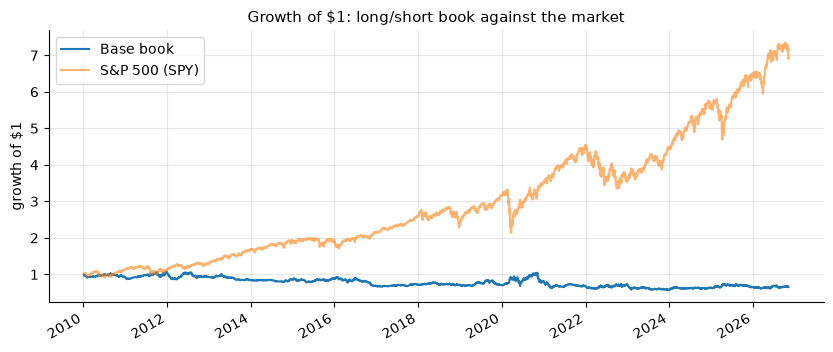

In [18]:
variants = {"Base book": lambda w, B, Sf, D, s: (w, pd.Series(dtype=float))}
ret_base, hist_base = rt.run_backtest(stock_px, stock_r, etf_r, F, variants, start="2010-01-01")
r_book = ret_base["Base book"]
stats_tab = pd.DataFrame({"Base book": du.annual_stats(r_book), "S&P 500 (SPY)": du.annual_stats(etf_r["SPY"].loc[r_book.index])}).T
stats_tab["turnover per rebalance"] = [np.mean([h["traded"] for h in hist_base["Base book"]]) / 2, np.nan]
print(f"{len(hist_base['Base book'])} rebalances, {r_book.index[0].date()} to {r_book.index[-1].date()}")
print(stats_tab.round(3).to_string())
fig, ax = plt.subplots(figsize=(10, 4))
(1 + r_book).cumprod().plot(ax=ax, label="Base book")
(1 + etf_r["SPY"].loc[r_book.index]).cumprod().plot(ax=ax, label="S&P 500 (SPY)", alpha=0.6)
ax.set(title="Growth of $1: long/short book against the market", ylabel="growth of $1", xlabel=""); ax.legend()
plt.show()

- Over 202 monthly rebalances from Jan 2010 to Nov 2026, the book lost 2.5% a year at 15.8% volatility (Sharpe ratio −0.16), with a worst drawdown of −46%. The S&P 500 returned 12.2% a year (Sharpe ratio 0.71).
- The book turns over about half its positions each month (0.51 per rebalance), so costs matter.
- A long/short book that loses money over 16 years is not a portfolio a PM would run. It is still a useful test case: the stress-testing toolkit should be able to say why it loses, which is the job a risk team does every month for real books.

## 3 · Where does today's risk come from?

The **factor risk model** explains each stock's daily return as exposure to the nine factors plus a stock-specific part:

r_stock = β₁·f₁ + … + β₉·f₉ + ε

The betas β come from a regression over the last year. Adding up the betas of all positions, weighted, gives the **book's exposure** to each factor. The book's variance then splits exactly into a part from each factor and a specific part, and the same split can be made by position. A position's **risk contribution** is its weight times its covariance with the book; contributions add up to 100% of the variance, and a negative one means the position hedges the rest.

Three ways to measure a bad day are compared:
- **Parametric VaR**: 2.33 × volatility, the 99% loss if returns were normal.
- **Historical VaR and expected shortfall (ES)**: today's weights applied to every day since 2008, then the 1% worst loss (VaR) and the average of losses beyond it (ES). Days before a stock existed use its factor-model return.

Ex-ante volatility 15.7% a year; factors 70% of variance, stock-specific 30%
                exposure (beta)  share of variance
MKT                      -0.161              0.051
SIZE                      0.020              0.002
VALUE                     0.560              0.289
MOM                       0.544              0.255
RATES                    -0.448              0.050
CREDIT                    0.269              0.006
OIL                       0.040              0.052
GOLD                      0.002             -0.000
USD                      -0.046             -0.003
Stock-specific              NaN              0.298

Largest risk contributors:
      weight         sector  share of variance
IBM   -0.064           Tech              0.080
AMZN  -0.060  Discretionary              0.061
NKE   -0.060  Discretionary              0.057
BKNG  -0.047  Discretionary              0.054
ADBE  -0.044           Tech              0.052
META  -0.042           Comm              0.047
CRM  

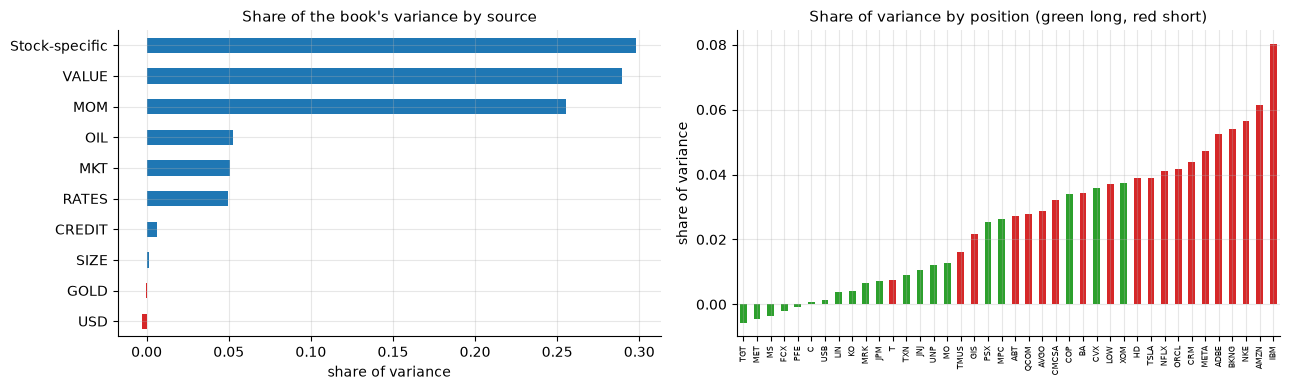

In [19]:
B, Sf, D = rt.risk_model(stock_r, F, asof)
w = w_now[w_now.index.intersection(B.index)]
b, fac_var, spec_var, tot_var, pos_var = rt.risk_decomposition(w, B, Sf, D)
vol_ann = np.sqrt(tot_var * 252)
risk_tab = pd.DataFrame({"exposure (beta)": b, "share of variance": fac_var / tot_var})
risk_tab.loc["Stock-specific"] = [np.nan, spec_var / tot_var]
print(f"Ex-ante volatility {vol_ann:.1%} a year; factors {fac_var.sum() / tot_var:.0%} of variance, stock-specific {spec_var / tot_var:.0%}")
print(risk_tab.round(3).to_string())

pos = pd.DataFrame({"weight": w, "sector": sector[w.index], "share of variance": pos_var / tot_var}).sort_values("share of variance", ascending=False)
print("\nLargest risk contributors:"); print(pos.head(8).round(3).to_string())
hedgers = pos[pos["share of variance"] < 0]
print("\nPositions that reduce risk (negative contribution):"); print(hedgers.round(3).to_string() if len(hedgers) else "none")

pnl_hs = rt.holdings_history(w, stock_r, F, B, start="2008-01-01")
var99, es99 = rt.var_es(pnl_hs, 0.99)
print(f"\n1-day 99%: parametric VaR {2.326 * np.sqrt(tot_var):.2%} | historical VaR {var99:.2%} | historical ES {es99:.2%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
risk_tab["share of variance"].sort_values().plot.barh(ax=axes[0], color=["C3" if v < 0 else "C0" for v in risk_tab["share of variance"].sort_values()])
axes[0].set(title="Share of the book's variance by source", xlabel="share of variance")
pos["share of variance"].sort_values().plot.bar(ax=axes[1], color=["C2" if v > 0 else "C3" for v in w[pos["share of variance"].sort_values().index]])
axes[1].set(title="Share of variance by position (green long, red short)", ylabel="share of variance"); axes[1].tick_params(axis="x", labelsize=6)
plt.tight_layout(); plt.show()

- Ex-ante volatility is 15.7% a year. Factors explain 70% of the variance and stock-specific risk 30%.
- Two factors dominate: value (exposure 0.56, 29% of variance) and momentum (0.54, 26%). The value exposure is the sector bet from section 2: long banks and energy, short technology and growth. It was never an intended bet.
- Rates (−0.45, 5%) means the book loses when bond yields fall, the typical exposure of a book long banks and short long-duration growth stocks. Market (−0.16) and oil add about 5% each.
- All eight largest risk contributors are shorts, led by IBM (8% of variance), AMZN, NKE, BKNG and ADBE. A few longs (PFE, FCX, MS, MET, TGT) slightly reduce risk.
- On a typical bad day, the 1-day 99% loss is 2.3% by both the normal formula and history, but the average loss beyond it (ES) is 3.0%. The normal model gets the threshold right and the depth of the tail wrong.

## 4 · Which risks has the book been paid for?

A VaR limit treats all risk as bad. A PM needs a different question answered: for each source of risk, did the book earn a return for carrying it? The 16-year backtest answers it. Each day's return is split into factor parts (the book's exposure at the last rebalance times that day's factor return) and a remainder, the return from stock selection. For each part:
- **Return contribution**: its average annual return.
- **Risk contribution**: its share of the book's variance, cov(part, book) / var(book).
- **Return per unit of risk**: its return divided by its own volatility. A part with a high ratio is worth its risk; one near zero or negative is risk without reward.

                 annual return  annual vol  share of variance  return / vol        paid?
MKT                     -0.019       0.030              0.068        -0.630     not paid
SIZE                     0.001       0.027              0.074         0.019  weakly paid
VALUE                    0.004       0.042              0.049         0.096  weakly paid
MOM                     -0.002       0.087              0.385        -0.018     not paid
RATES                   -0.000       0.019              0.002        -0.017     not paid
CREDIT                  -0.000       0.021              0.028        -0.008     not paid
OIL                      0.001       0.026              0.039         0.058  weakly paid
GOLD                    -0.010       0.015              0.008        -0.648     not paid
USD                      0.003       0.010              0.006         0.263  weakly paid
Stock selection          0.009       0.093              0.341         0.099  weakly paid

book: annual return 

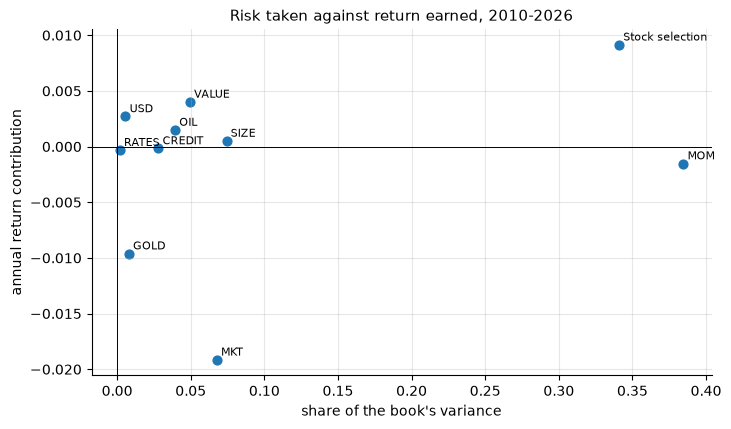

In [20]:
P = rt.factor_attribution(r_book, hist_base["Base book"], F)
attr = pd.DataFrame({"annual return": P.mean() * 252, "annual vol": P.std() * np.sqrt(252),
                     "share of variance": P.apply(lambda x: np.cov(x, r_book.loc[P.index])[0, 1]) / r_book.loc[P.index].var()})
attr["return / vol"] = attr["annual return"] / attr["annual vol"]
attr["paid?"] = np.where(attr["return / vol"] > 0.3, "paid", np.where(attr["return / vol"] > 0, "weakly paid", "not paid"))
print(attr.round(3).to_string())
print(f"\nbook: annual return {r_book.mean() * 252:.2%}; sum of parts {attr['annual return'].sum():.2%}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(attr["share of variance"], attr["annual return"], s=40)
for k in attr.index:
    ax.annotate(k, (attr.loc[k, "share of variance"], attr.loc[k, "annual return"]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.axhline(0, color="k", lw=0.7); ax.axvline(0, color="k", lw=0.7)
ax.set(title="Risk taken against return earned, 2010-2026", xlabel="share of the book's variance", ylabel="annual return contribution")
plt.show()

- The book's arithmetic return is −1.3% a year, and the parts add up to it exactly.
- Momentum carried the most risk, 39% of the book's variance, and earned nothing (−0.2% a year). The intended factor bet was not paid over 2010–2026.
- Stock selection carried 34% of the variance and earned +0.9% a year (0.10 per unit of volatility): weakly paid.
- The market exposure cost 1.9% a year (−0.63 per unit of volatility) and gold 1.0% (−0.65). These are small accidental exposures that lost steadily.
- No source of risk clears 0.3 per unit of volatility. The chart shows most risk sitting on the right with returns near zero: risk without reward.
- This view changes the question. Cutting risk at random would not cost return, because no risk was paid. The useful action is to find out why the intended bets fail, which section 9 tests.

### Are the riskiest stocks the return source?

The same question at the level of positions. Every stock that was ever held is placed by its average share of the book's ex-ante variance while held, and its total P&L contribution. If the riskiest names also earned the most, a rule that cuts the highest-VaR positions would cut the return.

In [21]:
risk_share, pnl = {}, {}
H = hist_base["Base book"]
for j, h in enumerate(H):
    end = H[j + 1]["date"] if j + 1 < len(H) else r_book.index[-1] + pd.Timedelta(days=1)
    idx = r_book.index[(r_book.index >= h["date"]) & (r_book.index < end)]
    Bj, Sfj, Dj = rt.risk_model(stock_r, F, h["date"] - pd.Timedelta(days=1))
    wj = h["w"][h["w"].index.intersection(Bj.index)]
    _, _, _, tv, pv = rt.risk_decomposition(wj, Bj, Sfj, Dj)
    for t in wj.index:
        risk_share.setdefault(t, []).append(pv[t] / tv)
    contrib = stock_r.loc[idx, h["w"].index].fillna(0.0).mul(h["w"]).sum()
    for t, v in contrib.items():
        pnl[t] = pnl.get(t, 0.0) + v
names = pd.DataFrame({"avg risk share": pd.Series({t: np.mean(v) for t, v in risk_share.items()}),
                      "months held": pd.Series({t: len(v) for t, v in risk_share.items()}), "P&L contribution": pd.Series(pnl)}).dropna()
names["sector"] = sector[names.index]
names["risk quintile"] = pd.qcut(names["avg risk share"].rank(method="first"), 5, labels=["1 lowest", "2", "3", "4", "5 highest"])
names["P&L per month held (bp)"] = names["P&L contribution"] / names["months held"] * 1e4
by_q = names.groupby("risk quintile", observed=True).agg(stocks=("P&L contribution", "size"), avg_risk_share=("avg risk share", "mean"),
                                                         total_PnL=("P&L contribution", "sum"), PnL_per_month_bp=("P&L per month held (bp)", "mean"),
                                                         share_positive=("P&L contribution", lambda x: (x > 0).mean()))
print(by_q.round(3).to_string())
print("\nTop 10 P&L contributors:"); print(names.sort_values("P&L contribution", ascending=False).head(10).round(3).to_string())

               stocks  avg_risk_share  total_PnL  PnL_per_month_bp  share_positive
risk quintile                                                                     
1 lowest           19          -0.001      0.430             2.865           0.789
2                  18           0.011      0.008             0.029           0.556
3                  18           0.020      0.210             1.269           0.556
4                  18           0.032     -0.315            -2.134           0.222
5 highest          18           0.050     -0.344            -1.887           0.333

Top 10 P&L contributors:
      avg risk share  months held  P&L contribution       sector risk quintile  P&L per month held (bp)
MO             0.003          107             0.095      Staples      1 lowest                    8.921
ADBE           0.046          104             0.091         Tech     5 highest                    8.725
GE             0.023          118             0.080  Industrials             3   

- The five buckets sort the 91 stocks ever held by their average share of the book's risk while held. Total P&L is each bucket's summed contribution over 2010–2026, as a share of capital.
- The two highest-risk buckets lost money (−0.315 and −0.344), and only 22% and 33% of their stocks made money while held. The lowest-risk bucket made +0.430, with 79% of its stocks positive.
- Per month held, the average stock in the lowest-risk bucket earned +2.9 bp of capital; in the two highest-risk buckets −2.1 bp and −1.9 bp. The result is the same when holding time is taken out, so it is not driven by how long names stayed in the book.
- Of the ten biggest earners, only ADBE is in the highest-risk bucket; four are in the lowest (MO, COST, T, JNJ).
- In this book the riskiest names were not the return source. That is the opposite of the case the study set out to protect, and it fits section 4: no risk was paid, so cutting the riskiest names would have helped.

## 5 · What would past crises do to today's book?

A **historical replay** applies today's weights to the actual daily returns of a past episode. It needs no model, and it captures moves no model would predict, such as a short squeeze. Stocks that did not exist yet use their factor-model return. Each loss is also split into the factor part (today's exposures times the factors' moves in that episode) and the stock-specific remainder, so the PM can see whether a loss comes from a bet that could be hedged.

Episodes are chosen to cover different kinds of stress: market crashes, rate shocks, momentum reversals and short squeezes. The **momentum crash** of Nov 9, 2020 (the vaccine announcement) and the **short squeeze** of late Jan 2021 hit long/short books that the market sell-offs barely touched.

In [22]:
EPISODES = [
    ("Global financial crisis", "2008-09-02", "2008-11-20", "market crash"),
    ("Momentum crash, 2009 rebound", "2009-03-09", "2009-05-29", "momentum reversal"),
    ("US downgrade", "2011-07-22", "2011-10-03", "market crash"),
    ("China devaluation", "2015-08-17", "2015-08-25", "market crash"),
    ("Election rotation", "2016-11-08", "2016-11-30", "momentum reversal"),
    ("Q4 2018 sell-off", "2018-10-01", "2018-12-24", "market crash"),
    ("COVID crash", "2020-02-19", "2020-03-23", "market crash"),
    ("Vaccine momentum crash", "2020-11-06", "2020-11-13", "momentum reversal"),
    ("Meme-stock short squeeze", "2021-01-22", "2021-02-02", "short squeeze"),
    ("2022 rate shock", "2022-01-03", "2022-06-16", "rates"),
    ("Regional bank failures", "2023-03-08", "2023-03-17", "credit"),
    ("Rotation and yen carry unwind", "2024-07-10", "2024-08-05", "momentum reversal"),
    ("Tariff shock", "2025-04-02", "2025-04-08", "market crash"),
]
R_all = stock_r[w.index].fillna(pd.DataFrame(F.reindex(stock_r.index).values @ B.loc[w.index].T.values, index=stock_r.index, columns=w.index))
rows = {}
for name, a, z, kind in EPISODES:
    seg = R_all.loc[a:z]
    if len(seg) == 0:
        continue
    book_ret = (1 + seg @ w).prod() - 1
    fac_part = float(b @ ((1 + F.loc[a:z]).prod() - 1))
    hist_ret = (1 + r_book.loc[a:z]).prod() - 1 if r_book.index[0] <= pd.Timestamp(a) else np.nan
    rows[name] = {"type": kind, "days": len(seg), "today's book": book_ret, "factor part": fac_part,
                  "stock-specific part": book_ret - fac_part, "book held then": hist_ret,
                  "S&P 500": (1 + etf_r["SPY"].loc[a:z]).prod() - 1}
replay = pd.DataFrame(rows).T
print(replay.to_string(formatters={c: "{:.1%}".format for c in ["today's book", "factor part", "stock-specific part", "book held then", "S&P 500"]}))

                                            type days today's book factor part stock-specific part book held then S&P 500
Global financial crisis             market crash   58       -12.4%        5.5%              -17.9%            NaN  -44.4%
Momentum crash, 2009 rebound   momentum reversal   58        21.0%       -9.1%               30.1%            NaN   33.4%
US downgrade                        market crash   51        -4.9%       -9.3%                4.4%           9.4%  -19.0%
China devaluation                   market crash    7        -2.2%        0.2%               -2.4%           2.8%  -10.7%
Election rotation              momentum reversal   16         6.9%        2.0%                4.9%         -10.1%    3.4%
Q4 2018 sell-off                    market crash   59         2.0%       -3.4%                5.4%          -5.1%  -19.4%
COVID crash                         market crash   24       -14.0%       -6.1%               -7.9%          19.1%  -35.4%
Vaccine momentum crash  

- Today's book would have lost 12.4% in the 2008 crisis, while the market fell 44%. The loss is almost all stock-specific (−17.9%): the book is long banks, and banks fell far more than their factor exposures predict.
- It would have lost 14.0% in the COVID crash (−6.1% from factors, −7.9% stock-specific) and 8.1% in the 2023 regional bank failures, almost all from factors (−9.0%).
- It would have gained 34.6% in the 2022 rate shock, nearly all from factors (+32.2%): long value and energy, short growth.
- In the momentum reversals of 2009 and Nov 2020, today's book gains (+21.0%, +7.5%), because today it is long value-like stocks that led those rebounds.
- The book actually held at the time had a different record: +19.1% in COVID, but −10.1% after the 2016 election and −10.8% in the Nov 2020 vaccine momentum crash. Its worst episodes were momentum reversals, not market crashes.
- A stress test of today's book depends on today's positions. The same strategy was exposed to different crises at different times, so a replay library should include momentum crashes and bank failures, not only market crashes.

## 6 · What do hypothetical shocks do?

History offers a limited set of crises. A **hypothetical scenario** sets the size of one or two shocks, for example oil +40%, and asks how the book would do. Shocking one factor alone is unrealistic: when oil jumps, other factors usually move too. The **conditional scenario** fills in the most likely move of every other factor given the shock, using the factor covariance Σ:

E[f_other | f_shocked = s] = Σ_os · Σ_ss⁻¹ · s

Two covariances are used: one from all days and one from stress days only, because correlations rise in a crisis (section 1). The book's loss is its factor exposure times the full scenario; stock-specific moves average out in expectation.

In [23]:
Sf_all = F.cov()
Sf_stress = F.loc[stress].cov()
SCENARIOS = {
    "Market falls 20%": {"MKT": -0.20},
    "Momentum crash: losers beat winners by 15%": {"MOM": -0.15},
    "Rates up about 100 bp (IEF -7%)": {"RATES": -0.07},
    "Oil +40%": {"OIL": 0.40},
    "Credit spreads widen (HYG -8% vs IEF)": {"CREDIT": -0.08},
    "Value beats growth by 10%": {"VALUE": 0.10},
    "Dollar +8%": {"USD": 0.08},
    "Stagflation: oil +30%, rates up, market -10%": {"OIL": 0.30, "RATES": -0.05, "MKT": -0.10},
    "Market falls 20% and momentum crashes": {"MKT": -0.20, "MOM": -0.15},
}
scen_rows, scen_moves = {}, {}
for name, shock in SCENARIOS.items():
    f_n, f_s = rt.conditional_scenario(Sf_all, shock), rt.conditional_scenario(Sf_stress, shock)
    contrib = b * f_s
    scen_rows[name] = {"book P&L, normal correlations": float(b @ f_n), "book P&L, stress correlations": float(b @ f_s),
                       "largest driver": contrib.abs().idxmax(), "driver's P&L": contrib[contrib.abs().idxmax()]}
    scen_moves[name] = f_s
scen = pd.DataFrame(scen_rows).T
print(scen.to_string(formatters={c: "{:.2%}".format for c in ["book P&L, normal correlations", "book P&L, stress correlations", "driver's P&L"]}))
print("\nFull factor moves under stress correlations:")
print(pd.DataFrame(scen_moves).T.round(3).to_string())

                                             book P&L, normal correlations book P&L, stress correlations largest driver driver's P&L
Market falls 20%                                                     1.63%                         1.85%            MOM        3.34%
Momentum crash: losers beat winners by 15%                          -5.41%                        -5.40%            MOM       -8.16%
Rates up about 100 bp (IEF -7%)                                      4.91%                         4.15%          RATES        3.13%
Oil +40%                                                             1.97%                         0.01%            MOM       -2.77%
Credit spreads widen (HYG -8% vs IEF)                               -1.17%                        -0.36%         CREDIT       -2.15%
Value beats growth by 10%                                            3.53%                         2.80%          VALUE        5.60%
Dollar +8%                                                           

- The worst scenarios are momentum crashes: −5.4% if losers beat winners by 15%, and −6.2% under stress correlations if that happens alongside a 20% market fall.
- A 20% market fall on its own would earn the book +1.9%, because the book is a little short the market and momentum tends to rise in a sell-off.
- Rising rates (+4.2%) and stagflation (+6.9%) help the book, again because it is long banks and energy and short long-duration growth stocks.
- Oil +40% is worth +2.0% with normal correlations and almost nothing (+0.0%) with stress correlations: in a crisis, an oil spike comes with other moves that cancel the gain. Credit widening shows a similar gap (−1.2% against −0.4%).
- The book is built to win in the scenarios a market-risk report worries about and to lose in the one it rarely tests: a reversal of recent winners and losers.

## 7 · How bad can a month get?

A one-day VaR from a normal distribution is the standard number, and it is the least informative. Four ways to simulate the book's P&L over the next 21 trading days, all using today's weights on returns since 2008:
- **Normal**: today's ex-ante volatility, normal distribution.
- **Block bootstrap**: resample the past in 5-day blocks, keeping fat tails and short runs of losses.
- **Filtered historical simulation (FHS)**: divide each past day by the volatility at the time (an exponentially weighted average with λ = 0.94), then multiply by today's volatility. This keeps the shape of past shocks but scales them to current conditions.
- **Stressed FHS**: the same, drawing only from stress days.

For each: the 99% one-month VaR and ES, as a share of capital.

                             VaR 99% ES 99% ES / normal ES
Normal                        10.66% 12.37%           1.00
Block bootstrap                9.71% 11.76%           0.95
Filtered historical           12.53% 14.20%           1.15
Stressed filtered historical  15.56% 17.64%           1.43


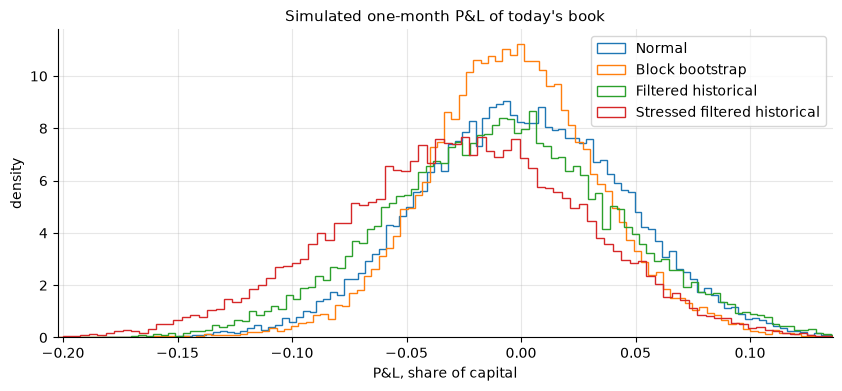


Positions that drive the worst days (1-day 99% ES):
     weight      sector  contribution to 1-day ES
C    0.0487  Financials                    0.0038
MET  0.0575  Financials                    0.0038
USB  0.0611  Financials                    0.0035
JPM  0.0635  Financials                    0.0032
MS   0.0456  Financials                    0.0027
COP  0.0400      Energy                    0.0018
CVX  0.0547      Energy                    0.0018
LIN  0.0783   Materials                    0.0017


In [24]:
pnl_hs = rt.holdings_history(w, stock_r, F, B, start="2008-01-01")
H21 = 21
sims = {
    "Normal": np.random.default_rng(0).normal(0, np.sqrt(tot_var * H21), 20000),
    "Block bootstrap": rt.bootstrap_paths(pnl_hs, H21),
    "Filtered historical": rt.fhs_paths(pnl_hs, H21),
    "Stressed filtered historical": rt.fhs_paths(pnl_hs, H21, pool=pnl_hs.index.intersection(stress)),
}
sim_tab = pd.DataFrame({k: dict(zip(["VaR 99%", "ES 99%"], rt.var_es(v, 0.99))) for k, v in sims.items()}).T
sim_tab["ES / normal ES"] = sim_tab["ES 99%"] / sim_tab.loc["Normal", "ES 99%"]
print(sim_tab.to_string(formatters={"VaR 99%": "{:.2%}".format, "ES 99%": "{:.2%}".format, "ES / normal ES": "{:.2f}".format}))

fig, ax = plt.subplots(figsize=(10, 4))
for k, v in sims.items():
    ax.hist(v, bins=120, histtype="step", density=True, label=k)
ax.set(title="Simulated one-month P&L of today's book", xlabel="P&L, share of capital", ylabel="density", xlim=(np.quantile(sims["Stressed filtered historical"], 0.001), np.quantile(sims["Block bootstrap"], 0.999)))
ax.legend(); plt.show()

ces = rt.component_es(w, R_all.loc["2008-01-01":].dropna(), 0.99)
ces_tab = pd.DataFrame({"weight": w, "sector": sector[w.index], "contribution to 1-day ES": ces}).sort_values("contribution to 1-day ES", ascending=False)
print("\nPositions that drive the worst days (1-day 99% ES):"); print(ces_tab.head(8).round(4).to_string())

- The one-month 99% loss is 10.7% under a normal distribution, 12.5% by filtered historical simulation and 15.6% when drawing only from stress days. The average loss beyond it (ES) is 12.4%, 14.2% and 17.6%.
- Stressed ES is 1.43 times the normal ES. The plain bootstrap is slightly lower than the normal model (11.8%) because it mixes today's positions with calm historical volatility; filtering rescales history to today's volatility and removes that bias.
- The worst days are driven by the long bank positions (C, MET, USB, JPM, MS), then energy (COP, CVX). None of them is among the largest contributors to everyday volatility in section 3, which were all shorts.
- The positions that decide the worst days are not the ones a volatility ranking flags. A tail-risk limit should be set on ES contributions, and a volatility-based cut would remove the wrong names.

## 8 · What is the most plausible way to lose 10% in a month?

A **reverse stress test** starts from the loss and works backwards: of all the factor moves that would make the book lose 10% in a month, which is the most likely? For a book whose factor P&L is the exposure vector b times the factor moves f, the answer has a closed form:

f* = −L · Σb / (bᵀΣb)

where L is the loss and Σ the monthly factor covariance. Its distance from normal conditions, in standard deviations, is L / σ_b, where σ_b is the book's monthly factor volatility. The test reports the scenario, how many standard deviations it is, and how often a month at least that bad would occur, under normal and under stress covariances. It covers factor risk only; stock-specific losses add to it.

In [25]:
LOSS = 0.10
rev = {}
for label, S in [("normal covariance", Sf_all * 21), ("stress covariance", Sf_stress * 21)]:
    f_star, n_sd, prob = rt.reverse_stress(b, S, LOSS)
    rev[label] = {"move": f_star, "in sd": f_star / np.sqrt(np.diag(S)), "n_sd": n_sd, "prob": prob}
    years = 1 / max(prob, 1e-12) / 12
    freq = f"about once every {years:,.0f} years" if years < 1000 else "less than once in 1,000 years"
    print(f"{label}: needs a {n_sd:.1f}-standard-deviation month; probability of a month at least this bad {prob:.3%} ({freq})")
rev_tab = pd.DataFrame({"move, normal cov": rev["normal covariance"]["move"], "in sd, normal": rev["normal covariance"]["in sd"],
                        "move, stress cov": rev["stress covariance"]["move"], "in sd, stress": rev["stress covariance"]["in sd"],
                        "book exposure": b})
rev_tab["P&L, stress cov"] = rev_tab["book exposure"] * rev_tab["move, stress cov"]
print(rev_tab.round(3).to_string())

normal covariance: needs a 3.3-standard-deviation month; probability of a month at least this bad 0.044% (about once every 190 years)
stress covariance: needs a 2.2-standard-deviation month; probability of a month at least this bad 1.537% (about once every 5 years)
        move, normal cov  in sd, normal  move, stress cov  in sd, stress  book exposure  P&L, stress cov
MKT                0.029          0.514             0.072          0.558         -0.161           -0.012
SIZE              -0.004         -0.115             0.011          0.206          0.020            0.000
VALUE             -0.044         -1.318            -0.028         -0.607          0.560           -0.016
MOM               -0.087         -1.867            -0.105         -1.326          0.544           -0.057
RATES              0.031          1.560             0.026          0.852         -0.448           -0.012
CREDIT            -0.024         -0.626            -0.018         -0.196          0.269           -0.005

- With normal correlations, losing 10% in a month through factor exposures takes a 3.3-standard-deviation month, about once every 190 years. With stress correlations it takes a 2.2-standard-deviation month, about once every 5 years.
- The most likely route to that loss is a momentum reversal: momentum falls 10.5% (−1.3 standard deviations) and causes 5.7 of the 10 points. Value falling 2.8% adds 1.6, a market rally of 7.2% costs 1.2 (the book is slightly short), and falling yields cost 1.2.
- Every factor in the scenario moves by less than 1.4 standard deviations. The loss needs no single extreme move, only an ordinary combination of moves against the book's main bets.
- The 10% loss is plausible, and its trigger is a momentum reversal combined with a market rally. That is the scenario to monitor and the exposure to size.

## 9 · Which re-allocation cuts stress losses without cutting return?

Six versions of the book, each rebuilt monthly. The first four use the same 40 names and sides; the last two change which names are held:
- **Base book**: inverse-volatility weights.
- **Minimum volatility**: the same names re-weighted to the lowest ex-ante volatility (longs +100%, shorts −100%, no position above 15%). This is what a pure risk-reduction mandate does.
- **Hedged**: the base book plus an ETF overlay that cancels every factor exposure except momentum, the intended factor bet. Stock-specific risk is kept.
- **Conviction-sized**: weights set so each position's share of risk is proportional to the strength of its score, so the strongest views carry the most risk.
- **Sector-neutral rebuild**: the same score, but ranked inside each sector: long the 2 best and short the 2 worst stocks in every sector. Sector bets cancel by construction, so the book keeps only the ranking within sectors. This tests whether the accidental sector bet from section 3 is what loses money.
- **Sector-neutral and hedged**: the sector-neutral book plus the same ETF overlay as the hedged version.

Each is judged on return, volatility, Sharpe ratio, drawdown, cost, and its losses in the historical episodes since 2010.

                           ann_return  ann_vol  sharpe  max_dd  turnover  avg ex-ante vol  avg |market beta|
Base book                      -0.025    0.158  -0.159  -0.464     0.511            0.124              0.157
Minimum volatility              0.005    0.118   0.043  -0.380     0.690            0.085              0.072
Hedged (keep momentum)         -0.011    0.133  -0.084  -0.429     0.923            0.089              0.000
Conviction-sized               -0.013    0.146  -0.092  -0.402     0.523            0.108              0.149
Sector-neutral rebuild          0.008    0.084   0.098  -0.189     0.509            0.075              0.074
Sector-neutral and hedged       0.011    0.080   0.138  -0.222     0.757            0.067              0.000

Losses in historical episodes:
                               Base book  Minimum volatility  Hedged (keep momentum)  Conviction-sized  Sector-neutral rebuild  Sector-neutral and hedged
US downgrade                        9.4%           

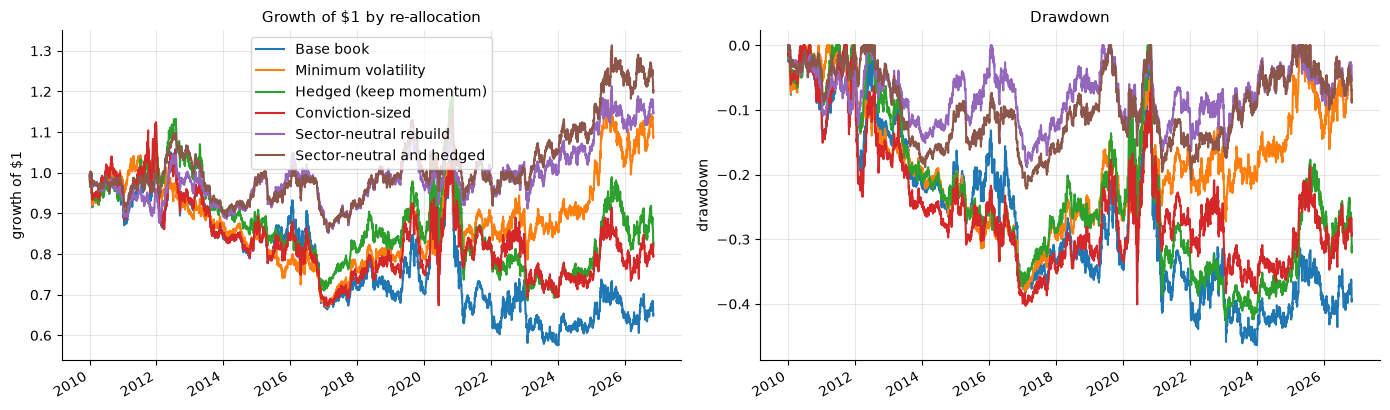

In [26]:
def v_base(w, B, Sf, D, s):
    return w, pd.Series(dtype=float)
def v_minvol(w, B, Sf, D, s):
    return rt.min_vol_weights(w, rt.asset_cov(B, Sf, D, w.index)), pd.Series(dtype=float)
def v_hedged(w, B, Sf, D, s):
    return w, rt.hedge_overlay(B.loc[w.index].T @ w, keep=("MOM",))
def v_conviction(w, B, Sf, D, s):
    return rt.risk_budget_weights(w, rt.asset_cov(B, Sf, D, w.index), s[w.index].abs()), pd.Series(dtype=float)
def v_sector_neutral(w, B, Sf, D, s):
    return rt.sector_neutral_book(s, B, Sf, D, sector), pd.Series(dtype=float)
def v_sector_neutral_hedged(w, B, Sf, D, s):
    ws = rt.sector_neutral_book(s, B, Sf, D, sector)
    return ws, rt.hedge_overlay(B.loc[ws.index].T @ ws, keep=("MOM",))
VARIANTS = {"Base book": v_base, "Minimum volatility": v_minvol, "Hedged (keep momentum)": v_hedged, "Conviction-sized": v_conviction,
            "Sector-neutral rebuild": v_sector_neutral, "Sector-neutral and hedged": v_sector_neutral_hedged}
ret_v, hist_v = rt.run_backtest(stock_px, stock_r, etf_r, F, VARIANTS, start="2010-01-01")
comp = pd.DataFrame({v: du.annual_stats(ret_v[v]) for v in ret_v}).T
comp["turnover"] = [np.mean([h["traded"] for h in hist_v[v]]) / 2 for v in ret_v]
comp["avg ex-ante vol"] = [np.mean([h["vol"] for h in hist_v[v]]) for v in ret_v]
comp["avg |market beta|"] = [np.mean([abs(h["b"]["MKT"]) for h in hist_v[v]]) for v in ret_v]
print(comp.round(3).to_string())

ep = {}
for name, a, z, kind in EPISODES:
    if pd.Timestamp(a) < ret_v.index[0]:
        continue
    ep[name] = {v: (1 + ret_v[v].loc[a:z]).prod() - 1 for v in ret_v}
ep = pd.DataFrame(ep).T
ep.loc["Average of episodes"] = ep.mean()
ep.loc["Worst episode"] = ep.iloc[:-1].min()
print("\nLosses in historical episodes:"); print(ep.to_string(float_format="{:.1%}".format))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
(1 + ret_v).cumprod().plot(ax=axes[0]); axes[0].set(title="Growth of $1 by re-allocation", ylabel="growth of $1", xlabel="")
dd = (1 + ret_v).cumprod() / (1 + ret_v).cumprod().cummax() - 1
dd.plot(ax=axes[1], legend=False); axes[1].set(title="Drawdown", ylabel="drawdown", xlabel="")
plt.tight_layout(); plt.show()

- **Minimum volatility:** return +0.5% a year against −2.5%, volatility 11.8% against 15.8%, Sharpe ratio 0.04 against −0.16, worst drawdown −38% against −46%. It trades more (0.69 per rebalance against 0.51).
- **Hedged (keep momentum):** return −1.1%, volatility 13.3%, Sharpe ratio −0.08. The overlay takes market exposure to zero and ex-ante volatility from 12.4% to 8.9%, but realised volatility stays at 13.3%: the losses come from the momentum bet and the stocks, which the hedge keeps. Turnover rises to 0.92.
- **Conviction-sized:** return −1.3%, Sharpe ratio −0.09, worst drawdown −40%.
- **Sector-neutral rebuild:** return +0.8%, volatility 8.4%, Sharpe ratio 0.10, worst drawdown −19%. It is the only version that roughly halves the drawdown, at the same turnover as the base book (0.51).
- **Sector-neutral and hedged:** return +1.1%, volatility 8.0%, Sharpe ratio 0.14, worst drawdown −22%, turnover 0.76.
- **Episodes.** The four versions that keep the original names all lost 7% to 11% in the November 2020 vaccine reversal. The sector-neutral rebuild lost 2.1%, and its worst episode is −3.5% (Q4 2018) against −10.8% for the base book. Most of the momentum-crash damage came from the sector bet riding on the momentum ranking, not from ranking stocks within sectors. The cost is the upside: the sector-neutral book made +0.9% in the COVID crash against +19.1%.
- Every version is better than the base book, which is what section 4 predicts: when no risk is paid, less risk or better-spread risk costs nothing. Removing the accidental bet helps more than any way of re-weighting the same names.

### Is the difference larger than luck?

Each re-allocation is compared with the base book on the same days. A moving-block bootstrap (21-day blocks, 2,000 resamples) gives a 90% interval for the difference in Sharpe ratio. A difference is credible only when its interval excludes zero.

In [27]:
def paired_sharpe_diff(a, b, block=21, n_boot=2000, seed=0):
    g = np.random.default_rng(seed)
    x = np.column_stack([a.values, b.values]); x = x[~np.isnan(x).any(axis=1)]
    n = len(x); nb = int(np.ceil(n / block))
    sr = lambda m: m.mean(0) / m.std(0) * np.sqrt(252)
    diffs = []
    for _ in range(n_boot):
        idx = np.concatenate([np.arange(s, s + block) for s in g.integers(0, n - block + 1, nb)])[:n]
        s = sr(x[idx]); diffs.append(s[0] - s[1])
    diffs = np.array(diffs); p = sr(x)
    return {"Sharpe difference": p[0] - p[1], "5%": np.quantile(diffs, 0.05), "95%": np.quantile(diffs, 0.95), "share ahead": (diffs > 0).mean()}
boot = pd.DataFrame({v: paired_sharpe_diff(ret_v[v], ret_v["Base book"]) for v in ret_v if v != "Base book"}).T
print("Sharpe ratio of each version minus the base book, daily returns, 21-day block bootstrap")
print(boot.round(3).to_string())

Sharpe ratio of each version minus the base book, daily returns, 21-day block bootstrap
                           Sharpe difference     5%    95%  share ahead
Minimum volatility                     0.184 -0.054  0.429        0.894
Hedged (keep momentum)                 0.065 -0.108  0.275        0.752
Conviction-sized                       0.062 -0.069  0.177        0.763
Sector-neutral rebuild                 0.222 -0.062  0.483        0.908
Sector-neutral and hedged              0.259 -0.036  0.563        0.923


- Ahead of the base book: sector-neutral and hedged by 0.26 (90% interval −0.04 to +0.56, ahead in 92% of resamples); sector-neutral rebuild by 0.22 (−0.06 to +0.48, 91%); minimum volatility by 0.18 (−0.05 to +0.43, 89%); hedged by 0.07 (−0.11 to +0.28, 75%); conviction sizing by 0.06 (−0.07 to +0.18, 76%).
- The Sharpe ratios here come from daily returns, so they differ slightly from the table above.
- Every interval includes zero. The sector-neutral versions are the most likely improvements, but over 16 years none of the gains can be told apart from luck at the 90% level.

## 10 · The risk report

The sections above end in one table a PM can read in a minute. For each source of risk in today's book it shows the exposure, its share of today's variance, whether it was paid over 16 years, its worst loss across the historical replays and hypothetical scenarios, and a suggested action:
- **Keep and size**: an intended bet that has been paid. Manage it with position sizes and loss limits, not with hedges.
- **Review the signal**: an intended bet that has not been paid. The problem is the signal, and no hedge fixes it.
- **Hedge**: an unintended exposure that has not been paid and is large enough to matter (above 5% of variance or 1% of stress loss). Cancel it with the ETF overlay.
- **Decide: keep deliberately or hedge**: an unintended exposure that happened to pay. Keeping it is a choice the PM should make explicitly.
- **Monitor**: an unintended exposure too small to matter.

In [28]:
worst = {}
for k in F.columns:
    hist_loss = min(float(b[k] * ((1 + F.loc[a:z, k]).prod() - 1)) for _, a, z, _ in EPISODES)
    scen_loss = min(float(b[k] * scen_moves[s][k]) for s in scen_moves)
    worst[k] = min(hist_loss, scen_loss)
report = pd.DataFrame({"factor": [rt.FACTOR_NAMES[k] for k in F.columns], "exposure": b[F.columns],
                       "share of variance": (fac_var / tot_var)[F.columns], "return / vol since 2010": attr.loc[F.columns, "return / vol"],
                       "worst stress P&L": pd.Series(worst)}, index=F.columns)
spec_row = pd.DataFrame({"factor": ["Stock selection (specific)"], "exposure": [np.nan], "share of variance": [spec_var / tot_var],
                         "return / vol since 2010": [attr.loc["Stock selection", "return / vol"]], "worst stress P&L": [np.nan]}, index=["SPECIFIC"])
report = pd.concat([report, spec_row])
INTENDED = {"MOM", "SPECIFIC"}                    # the bets the book is built to take
report["intended bet"] = ["yes" if k in INTENDED else "no" for k in report.index]
def action(r):
    paid = r["return / vol since 2010"] > 0.3
    material = abs(r["share of variance"]) > 0.05 or (pd.notna(r["worst stress P&L"]) and r["worst stress P&L"] < -0.01)
    if r.name in INTENDED:
        return "Keep and size" if paid else "Review the signal"
    if not material:
        return "Monitor"
    return "Decide: keep deliberately or hedge" if paid else "Hedge"
report["action"] = report.apply(action, axis=1)
print(f"Risk report as of {asof.date()}: ex-ante volatility {vol_ann:.1%}; 1-month 99% ES {sim_tab.loc['Stressed filtered historical', 'ES 99%']:.1%} (stressed); "
      f"10% factor loss needs a {rev['stress covariance']['n_sd']:.1f}-sd month under stress correlations")
print(report.to_string(formatters={"exposure": "{:.2f}".format, "share of variance": "{:.1%}".format,
                                   "return / vol since 2010": "{:.2f}".format, "worst stress P&L": "{:.1%}".format}))

Risk report as of 2026-11-06: ex-ante volatility 15.7%; 1-month 99% ES 17.6% (stressed); 10% factor loss needs a 2.2-sd month under stress correlations
                                   factor exposure share of variance return / vol since 2010 worst stress P&L intended bet             action
MKT                             US market    -0.16              5.1%                   -0.63            -5.4%           no              Hedge
SIZE               Small minus large caps     0.02              0.2%                    0.02            -0.2%           no            Monitor
VALUE                  Value minus growth     0.56             28.9%                    0.10            -4.1%           no              Hedge
MOM       Momentum (winners minus losers)     0.54             25.5%                   -0.02           -18.8%          yes  Review the signal
RATES         Treasury bonds (rates down)    -0.45              5.0%                   -0.02            -4.4%           no              He

- The report lists five unintended exposures to hedge: value (29% of variance, worst stress loss −4.1%), market (5%, −5.4%), rates (5%, −4.4%), oil (5%, −2.4%) and credit (worst stress loss −9.7%).
- Both intended bets, momentum and stock selection, are marked "Review the signal": together they carry 55% of the variance and earned close to nothing since 2010. Momentum also has the worst stress loss in the table (−18.8%).
- Size, gold and dollar are small enough to monitor.
- The table makes the book's problem readable at a glance: most of its risk comes from an accidental sector and value bet, and the bets it was designed to take have not paid. Hedging fixes the first problem; only a better signal fixes the second.

## Conclusions

**What holds**
- The toolkit separates intended from accidental risk. Most of this book's risk (70% from factors) came from an accidental value and sector bet created by the stability score, not from the momentum and stock picks it was built on (section 3).
- Neither intended bet was paid over 2010–2026: momentum carried 39% of the variance for −0.2% a year, stock selection 34% for +0.9% (section 4). The riskiest stocks lost money and the safest made it.
- The book's worst days come from long bank positions, not from the volatile shorts that dominate everyday risk (section 7), and its most plausible 10% loss is a momentum reversal with a market rally, about once every 5 years under stress correlations (section 8).
- Scenario losses change sign and size between normal and stress correlations (section 6), so both should be reported.

**What does not hold**
- The premise that the riskiest positions are the return source does not hold for this book. Here a VaR-driven cut would have helped: minimum volatility lifted the Sharpe ratio from −0.16 to +0.04 (section 9).
- Re-weighting the same names does not fix the book. The four versions that keep the original names all lost 7% to 11% in the November 2020 momentum reversal.
- Removing the accidental sector bet does most of the work: the sector-neutral rebuild cut the worst drawdown from −46% to −19% and the worst episode from −10.8% to −3.5%. It still earns only 0.8% a year, and none of the gains is statistically clear (section 9).

**How to use it**
1. Split the book's risk into factors and stock-specific risk before acting on any VaR number.
2. Judge every source of risk by what it has earned per unit of risk, not by its size alone.
3. Remove unintended bets at the source (here, rank stocks within sectors) before hedging them with ETFs; review intended bets that are not paid, since no hedge fixes them.
4. Replay crises that hit long/short books specifically (momentum crashes, short squeezes), not only market crashes.
5. Run scenarios with stress correlations, simulate with fat tails, and use a reverse stress test to name the scenario that would cause an unacceptable loss.

**Limitations.** The stock list holds today's large caps, so returns are flattering. The book has no positive edge, so it cannot show the case where risky positions earn their risk. Factor exposures come from one year of daily data. Scenarios assume a linear book with no liquidity costs.

**Next steps.** A book with a working return source and sector limits built into the optimiser; sector factors in the risk model; days-to-liquidate from trading volume.